# Register Fault Injection — Resilience Analysis
**Model:** Fashion-MNIST Image Classification (INT8 quantized TFLite)  
**Target:** RISC-V registers (transient bit-flip)  
**Campaign:** `registerfi_image_classification_fashsion_mnist_transient`  
**Sampling:** Stratified per operator — 95% confidence, 5% margin

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path(".")  # notebook lives inside the run directory

SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50",
    "Good": "#81C784",
    "Acceptable": "#FFC107",
    "Warning": "#FF9800",
    "Critical": "#F44336",
    "Crash": "#B71C1C",
}

CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

## 1. Data Loading

In [2]:
df = pd.read_csv(RUN_DIR / "classified_results.csv")
pop = pd.read_csv(RUN_DIR / "register_population.csv")
sel = pd.read_csv(RUN_DIR / "selected_register_faults.csv")
sel_by_layer = pd.read_csv(RUN_DIR / "selected_register_faults_by_layer.csv")
pop_by_op = pd.read_csv(RUN_DIR / "register_population_by_operator.csv")
operators = pd.read_csv(RUN_DIR / "all_operator_instances.csv")

import json
with open(RUN_DIR / "run_manifest.json") as f:
    manifest = json.load(f)

# Merge register metadata into classified results
reg_meta = sel[["fault_id", "register_name", "register_class", "register_id"]].drop_duplicates("fault_id")
df = df.merge(reg_meta, on="fault_id", how="left", suffixes=("", "_meta"))

# Ensure register_name and register_class columns are populated
if "register_name_meta" in df.columns:
    df["register_name"] = df["register_name"].fillna(df["register_name_meta"])
if "register_class" not in df.columns and "register_class_meta" in df.columns:
    df["register_class"] = df["register_class_meta"]

print(f"Total classified results : {len(df):,}")
print(f"Unique faults injected   : {df['fault_id'].nunique():,}")
print(f"Images per fault         : {len(df) // df['fault_id'].nunique()}")
print(f"Population size          : {len(pop):,}")
print(f"Operators targeted       : {df['operator_index'].nunique()}")
print(f"Registers targeted       : {df['register_name'].nunique()}")
print(f"Fault model              : {manifest.get('campaign_type', 'register')}")
print(f"Fault duration           : {manifest.get('fault_duration', 'transient')}")
df.head(3)

Total classified results : 139,000
Unique faults injected   : 1,390
Images per fault         : 100
Population size          : 4,960
Operators targeted       : 5
Registers targeted       : 31
Fault model              : register
Fault duration           : transient


,event,phase,mode,fault_model,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,...,delay_us,bit_index,mean_duration_us,samples,golden_pred_class_ref,golden_top1_prob_ref,fault_class,register_name_meta,register_class,register_id_meta
0,result,fault,fault,register,3.0,0.0,NaN,-1.0,0.0,NaN,...,NaN,3.0,NaN,NaN,9.0,0.929688,Crash,ra,caller_saved,0
1,result,fault,fault,register,3.0,1.0,NaN,-1.0,0.0,NaN,...,NaN,3.0,NaN,NaN,8.0,0.996094,Crash,ra,caller_saved,0
2,result,fault,fault,register,3.0,2.0,NaN,-1.0,0.0,NaN,...,NaN,3.0,NaN,NaN,7.0,0.996094,Crash,ra,caller_saved,0


## 2. Overall Fault Classification Distribution

,Count,Percentage (%)
fault_class,,
Masked,66243.0,47.66
Acceptable,4387.0,3.16
Warning,4493.0,3.23
Critical,10227.0,7.36
Crash,53650.0,38.60
TOTAL,139000.0,100.00


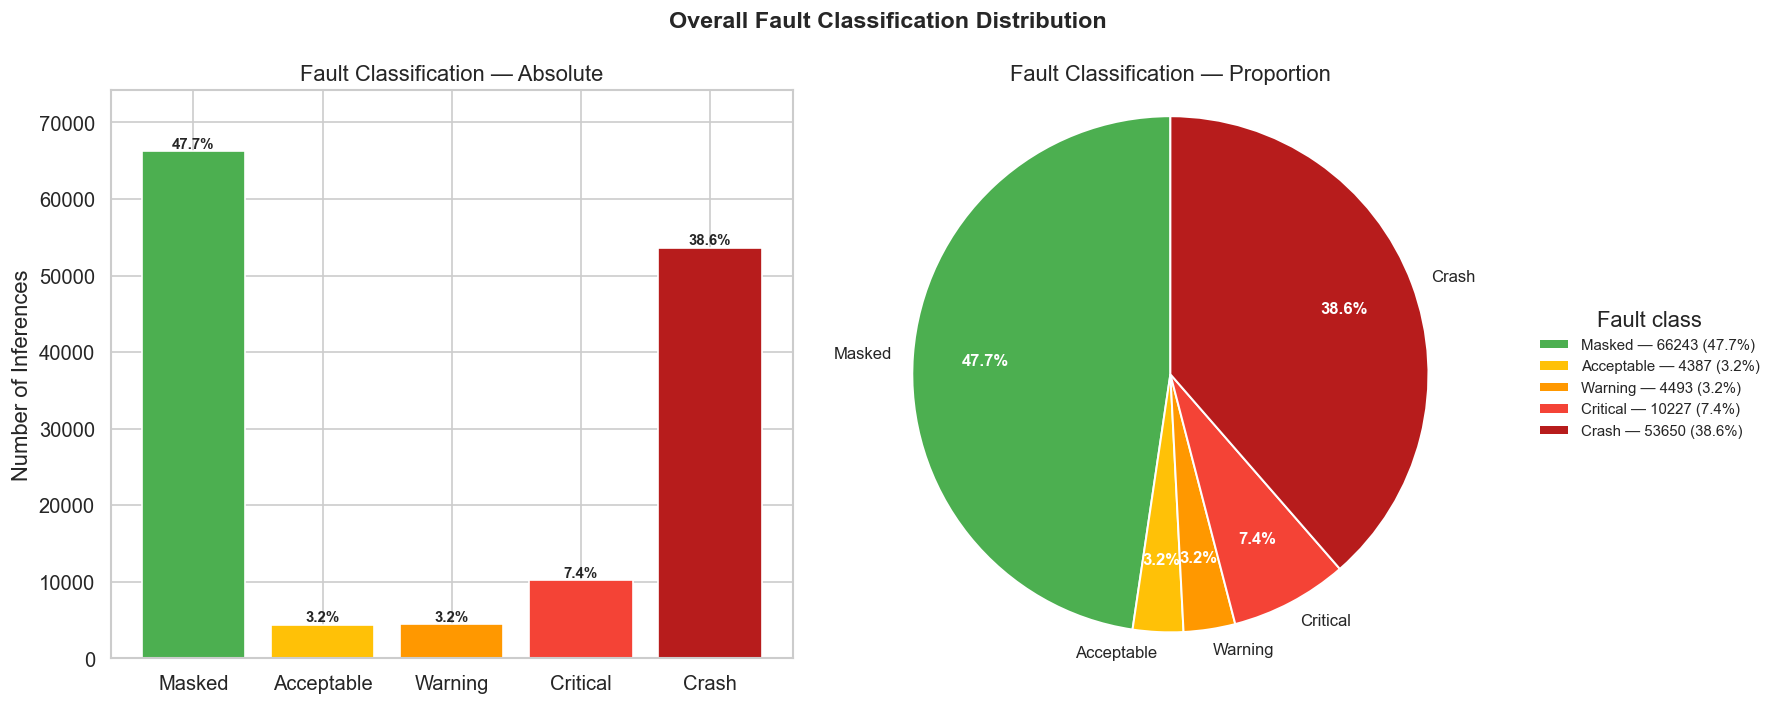

In [3]:
fc_counts = df["fault_class"].value_counts()
fc_ordered = fc_counts.reindex(SEVERITY_ORDER).dropna().astype(int)
fc_pct = fc_ordered / len(df) * 100

summary_table = pd.DataFrame({"Count": fc_ordered, "Percentage (%)": fc_pct.round(2)})
summary_table.loc["TOTAL"] = [len(df), 100.0]
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
colors = [SEVERITY_COLORS.get(c, "#999") for c in fc_ordered.index]
bars = axes[0].bar(fc_ordered.index, fc_ordered.values, color=colors, edgecolor="white")
for bar, pct in zip(bars, fc_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Number of Inferences")
axes[0].set_title("Fault Classification — Absolute")
axes[0].margins(y=0.12)

# Pie chart — rótulos só para fatias >= 3%, demais vão só na legenda
THRESH = 3.0  # %

def _autopct(pct):
    return f"{pct:.1f}%" if pct >= THRESH else ""

pie_labels = [name if pct >= THRESH else "" for name, pct in zip(fc_ordered.index, fc_pct.values)]

wedges, texts, autotexts = axes[1].pie(
    fc_ordered.values,
    labels=pie_labels,
    colors=colors,
    autopct=_autopct,
    startangle=90,
    pctdistance=0.72,
    labeldistance=1.08,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=10),
)
for t in autotexts:
    t.set_fontweight("bold")
    t.set_color("white")

axes[1].set_title("Fault Classification — Proportion")
axes[1].axis("equal")

# Legenda completa (inclui fatias pequenas omitidas do gráfico)
legend_labels = [f"{name} — {cnt} ({pct:.1f}%)"
                 for name, cnt, pct in zip(fc_ordered.index, fc_ordered.values, fc_pct.values)]
axes[1].legend(
    wedges, legend_labels,
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9,
    frameon=False,
)

fig.suptitle("Overall Fault Classification Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_overall_classification.png", bbox_inches="tight")
plt.show()

## 3. Resilience per Register

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
register_name,,,,,,,,
sp,4400,0,0,0,0,4400,1.0000,1.0000
gp,5000,0,0,0,0,5000,1.0000,1.0000
ra,3800,400,0,0,0,3400,0.8947,0.8947
s0,4200,960,126,146,192,2776,0.7067,0.7414
a2,5000,1052,252,225,406,3065,0.6942,0.7392
s3,4100,1241,133,132,498,2096,0.6327,0.6649
t6,3700,1171,187,205,737,1400,0.5776,0.6330
a1,4700,1095,389,527,989,1700,0.5721,0.6843
a4,4200,1013,329,524,1334,1000,0.5557,0.6805


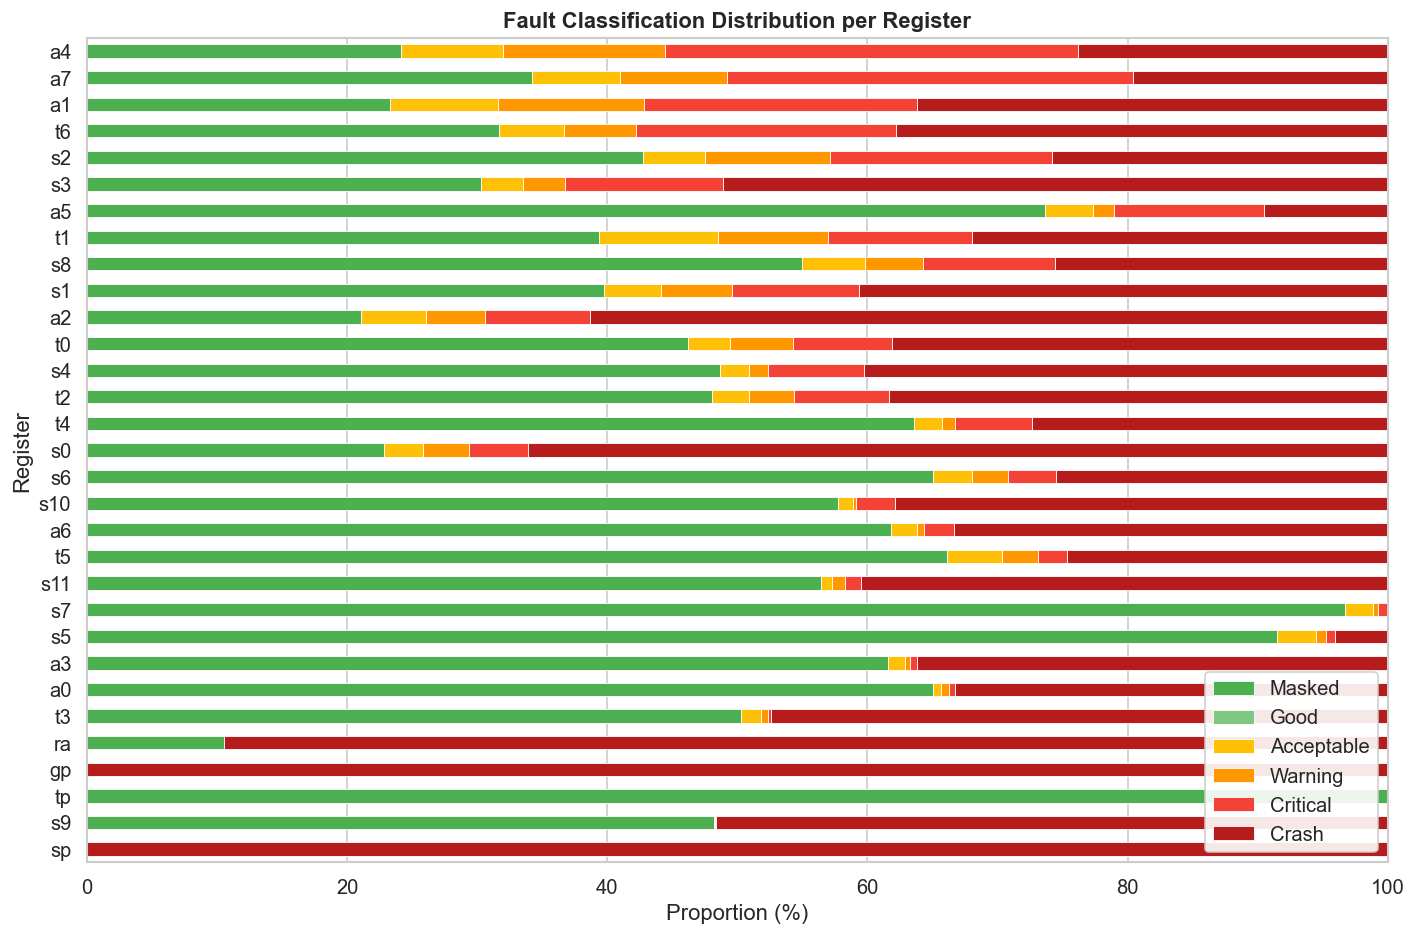

In [4]:
# Aggregate fault class distribution per register
reg_fc = df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
reg_fc = reg_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
reg_fc["total"] = reg_fc.sum(axis=1)
reg_fc["critical_rate"] = (reg_fc.get("Critical", 0) + reg_fc.get("Crash", 0)) / reg_fc["total"]
reg_fc["degraded_rate"] = reg_fc[[c for c in DEGRADED_SET if c in reg_fc.columns]].sum(axis=1) / reg_fc["total"]
reg_fc = reg_fc.sort_values("critical_rate", ascending=False)

display(reg_fc[["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]].round(4))

# Stacked bar — percentage per register
reg_pct = reg_fc[SEVERITY_ORDER].div(reg_fc["total"], axis=0) * 100
reg_pct_sorted = reg_pct.sort_values("Critical", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
reg_pct_sorted.plot.barh(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white", linewidth=0.5,
)
ax.set_xlabel("Proportion (%)")
ax.set_ylabel("Register")
ax.set_title("Fault Classification Distribution per Register", fontweight="bold")
ax.legend(loc="lower right", framealpha=0.9)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_register.png", bbox_inches="tight")
plt.show()

## 4. Resilience per Register Class
Registers are grouped by their RISC-V ABI classification: **caller-saved** (temporary), **callee-saved** (preserved), and **special** (sp, gp, tp, ra).

fault_class,Masked,Good,Acceptable,Warning,Critical,Crash,total,critical_rate,degraded_rate
register_class,,,,,,,,,
callee_saved,30195,0,1480,1486,3118,18321,54600,0.3927,0.4199
caller_saved,32048,0,2907,3007,7109,25929,71000,0.4653,0.5077
special,4000,0,0,0,0,9400,13400,0.7015,0.7015


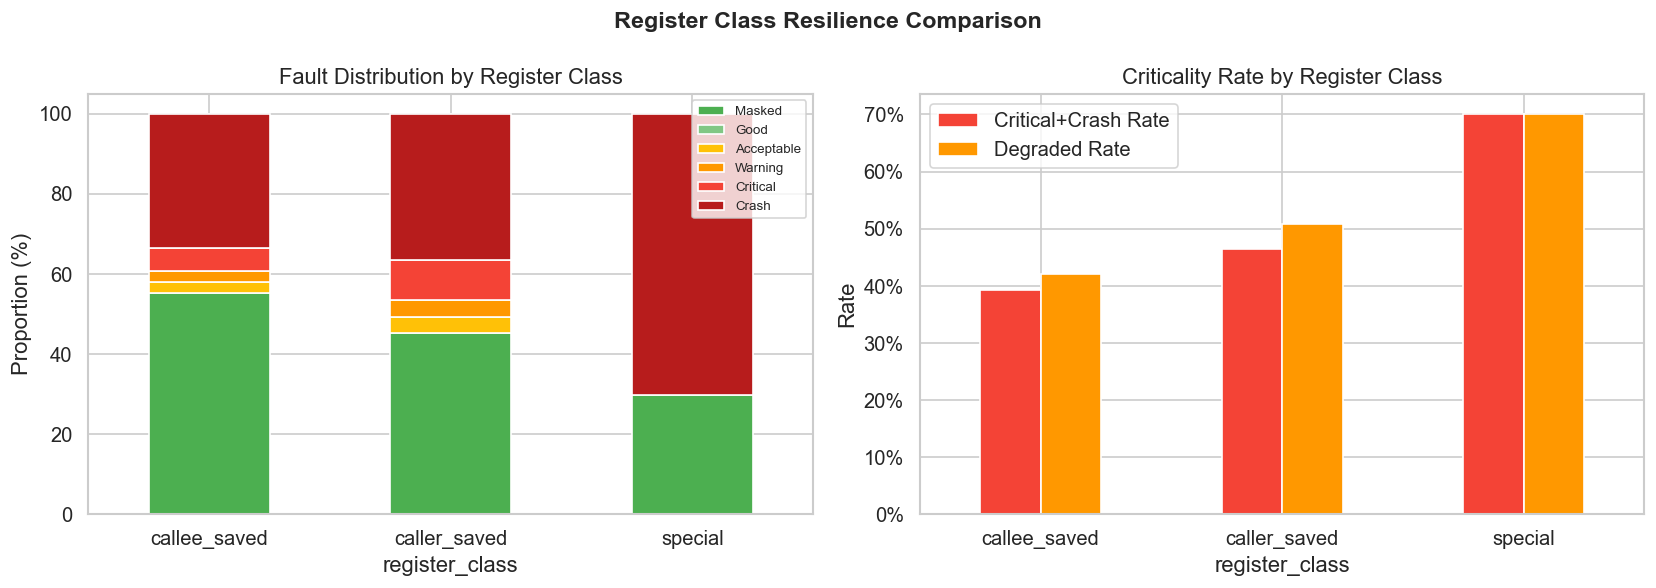

In [5]:
cls_fc = df.groupby("register_class")["fault_class"].value_counts().unstack(fill_value=0)
cls_fc = cls_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
cls_fc["total"] = cls_fc.sum(axis=1)
cls_fc["critical_rate"] = (cls_fc.get("Critical", 0) + cls_fc.get("Crash", 0)) / cls_fc["total"]
cls_fc["degraded_rate"] = cls_fc[[c for c in DEGRADED_SET if c in cls_fc.columns]].sum(axis=1) / cls_fc["total"]

display(cls_fc.round(4))

cls_pct = cls_fc[SEVERITY_ORDER].div(cls_fc["total"], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cls_pct.plot.bar(
    stacked=True, ax=axes[0],
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
axes[0].set_ylabel("Proportion (%)")
axes[0].set_title("Fault Distribution by Register Class")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(axis="x", rotation=0)

# Critical + Crash rate comparison
cls_crit = cls_fc[["critical_rate", "degraded_rate"]].copy()
cls_crit.columns = ["Critical+Crash Rate", "Degraded Rate"]
cls_crit.plot.bar(ax=axes[1], color=["#F44336", "#FF9800"], edgecolor="white")
axes[1].set_ylabel("Rate")
axes[1].set_title("Criticality Rate by Register Class")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Register Class Resilience Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_register_class_resilience.png", bbox_inches="tight")
plt.show()

## 5. Resilience per Operator (Layer)

In [6]:
df.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'elapsed_ms',
       'timeout_ms', 'boot_seen', 'result_seen', 'job_ack_seen',
       'recovery_method', 'inferred', 'operator_index', 'operator_name',
       'register_id', 'register_name', 'time_slot_index', 'time_slot_count',
       'delay_us', 'bit_index', 'mean_duration_us', 'samples',
       'golden_pred_class_ref', 'golden_top1_prob_ref', 'fault_class',
       'register_name_meta', 'register_class', 'register_id_meta'],
      dtype='object')

In [7]:
df['operator_index'].value_counts()

operator_index
0.0     27800
3.0     27800
6.0     27800
12.0    27800
14.0    27800
Name: count, dtype: int64

In [8]:
d = pd.read_csv('results.csv')

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\1667207595.py:1: DtypeWarning: Columns (15,16,17,19) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv('results.csv')


In [9]:
d.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'elapsed_ms',
       'timeout_ms', 'boot_seen', 'result_seen', 'job_ack_seen',
       'recovery_method', 'inferred', 'operator_index', 'operator_name',
       'register_id', 'register_name', 'time_slot_index', 'time_slot_count',
       'delay_us', 'bit_index', 'mean_duration_us', 'samples'],
      dtype='object')

In [10]:
d['operator_name'].value_counts()

operator_name
CONV_2D            83403
FULLY_CONNECTED    55602
Name: count, dtype: int64

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
CONV_2D,83400,38195,2567,2146,4803,35689,0.4855,0.5112
FULLY_CONNECTED,55600,28048,1820,2347,5424,17961,0.4206,0.4628


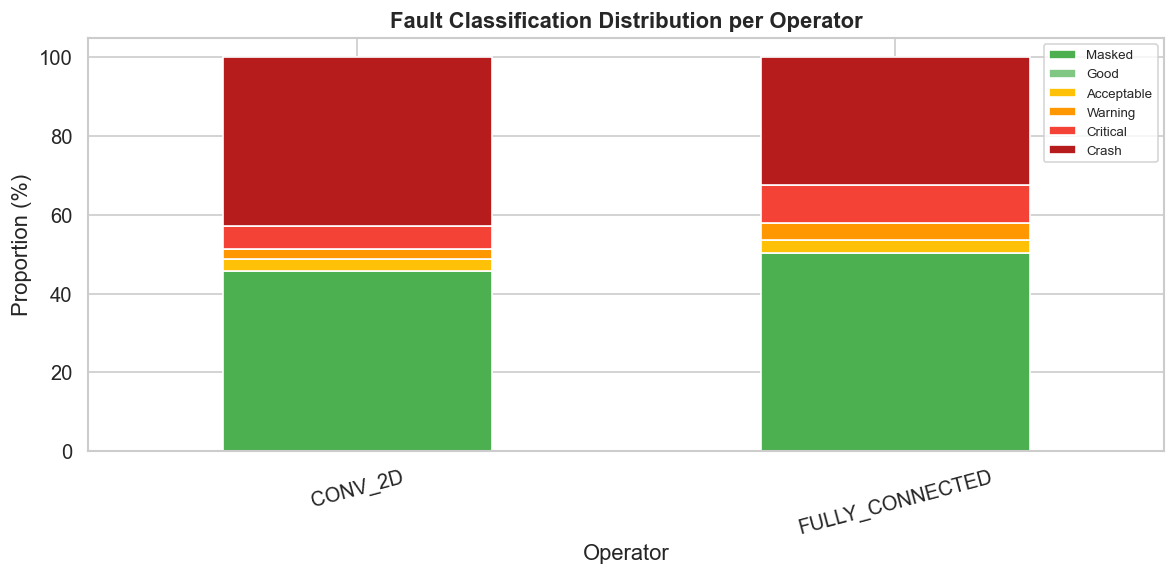

In [11]:
import numpy as np

# Usa apenas o nome real do operador
df["op_label"] = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

op_fc = op_fc.sort_values("critical_rate", ascending=False)

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den, axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator")
ax.set_title("Fault Classification Distribution per Operator", fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 6. Register × Operator Criticality Heatmap

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\2925067920.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)
C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\2925067920.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=Fal

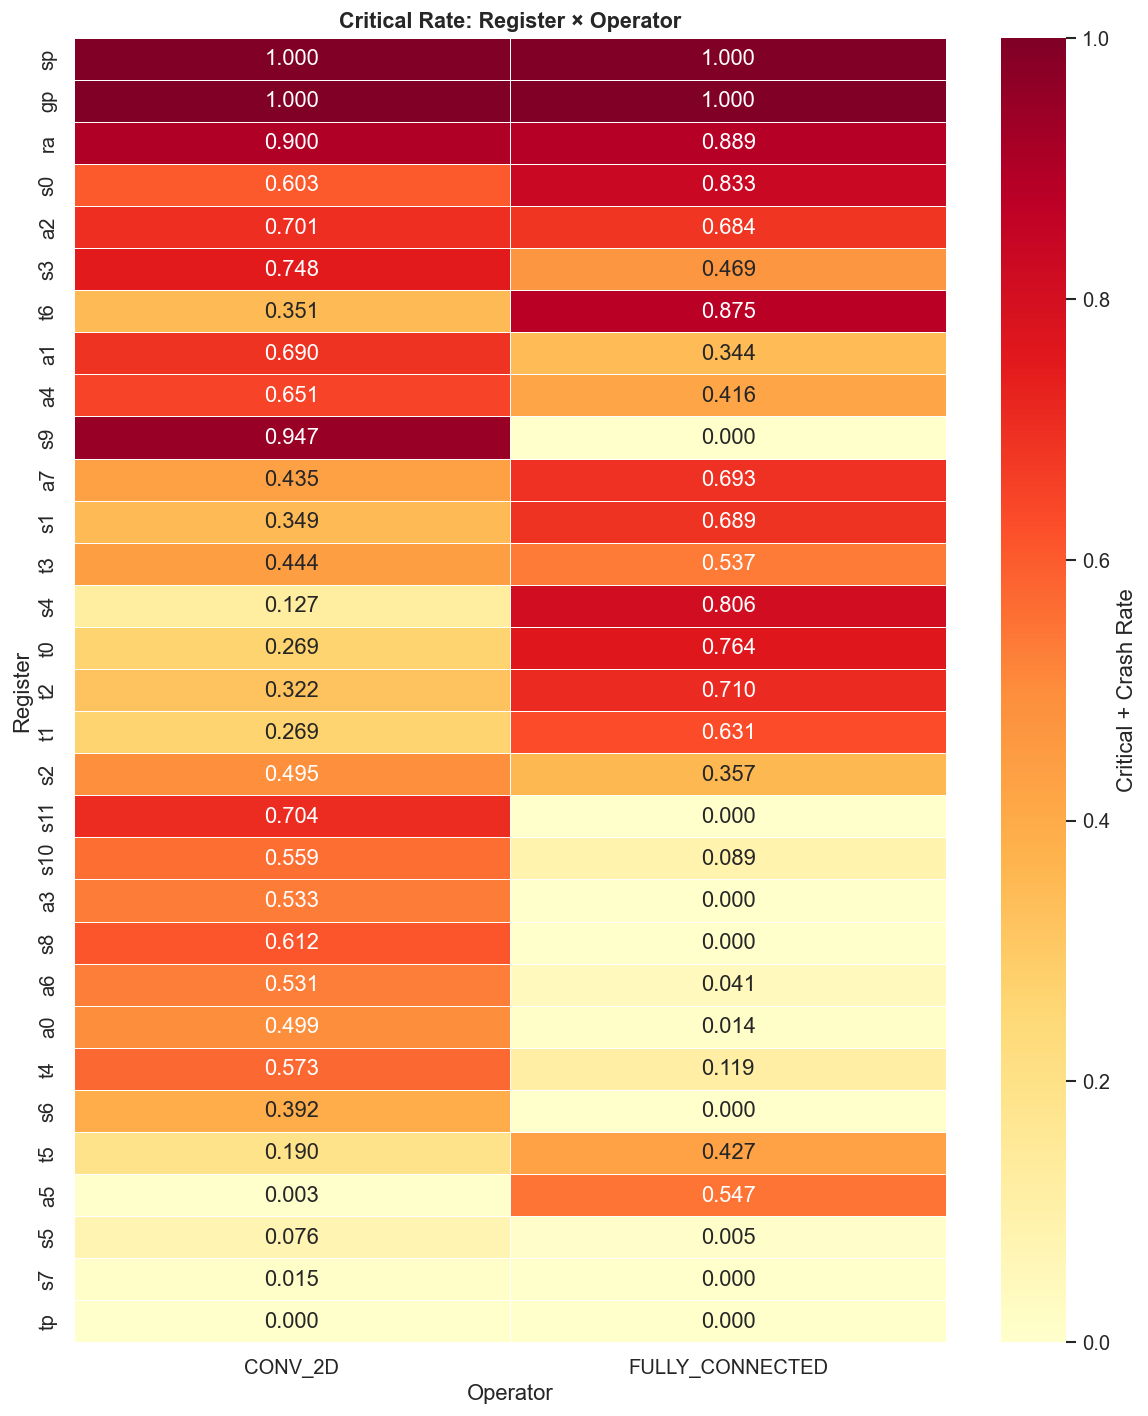

In [12]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)

# Sort registers by overall critical rate
reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=False).index
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\3847261106.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(critical_rate)
C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\3847261106.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("register_name").apply(critical_rate)


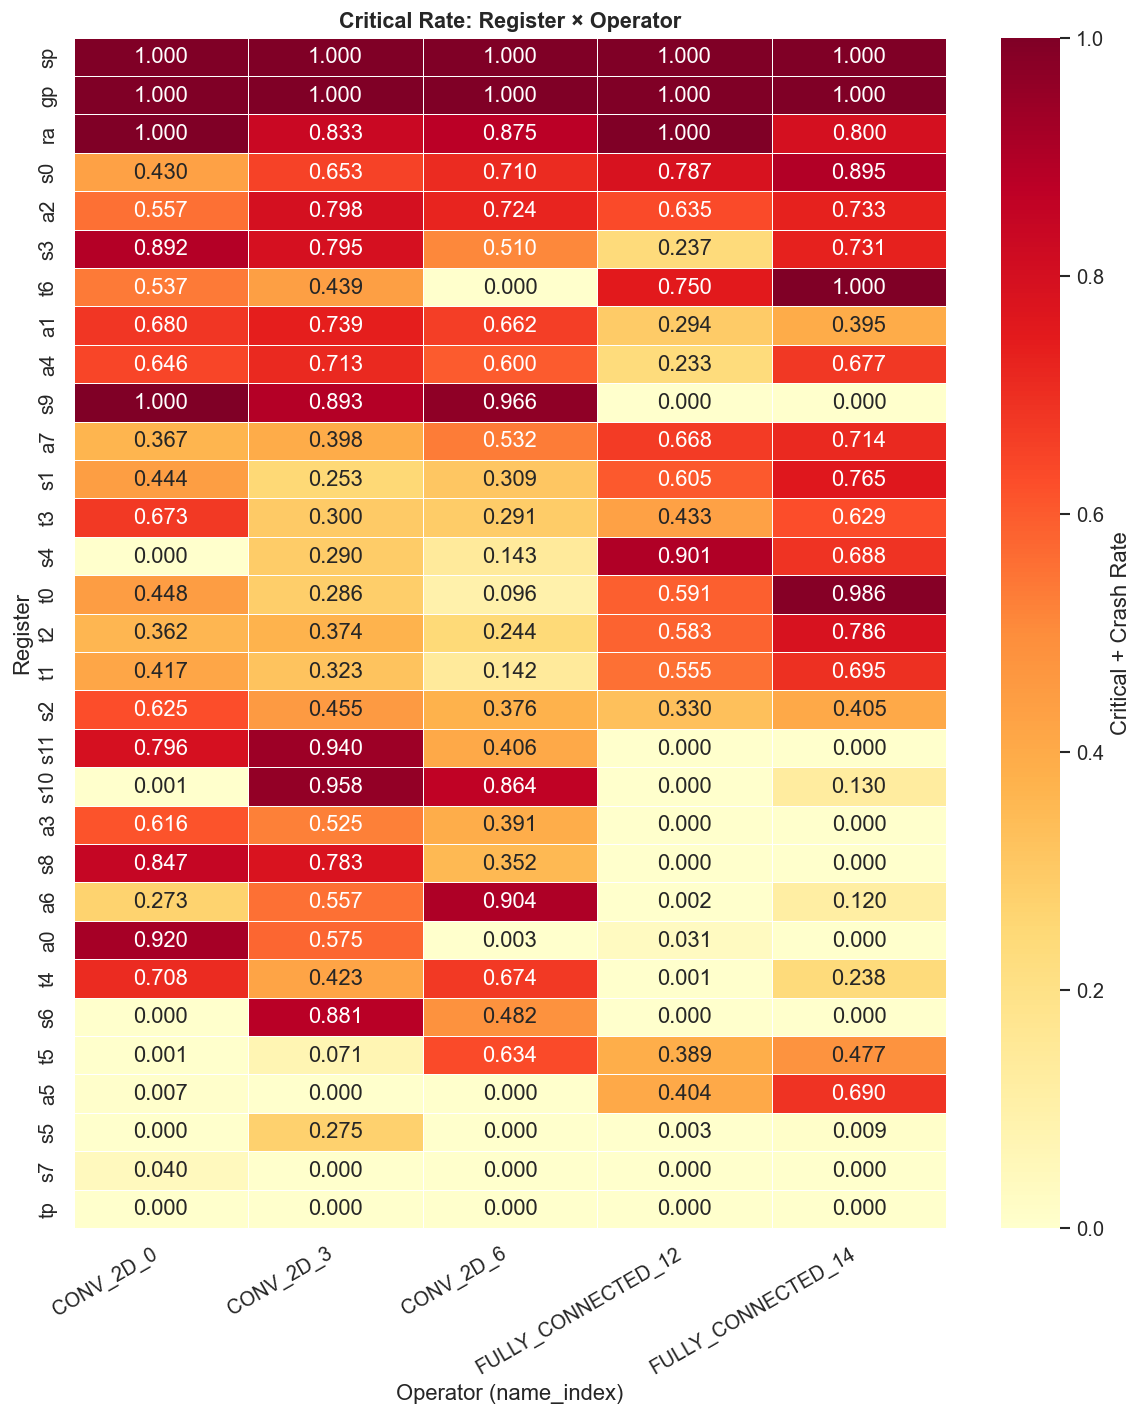

In [13]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Build "operator_name_operator_index" label (e.g. CONV_2D_0, CONV_2D_2)
op_name = (
    df["operator_name"].astype("string").str.strip()
    .replace("", pd.NA).fillna("Unknown")
)
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64").astype("string").fillna("NA")
)
df["op_full"] = op_name + "_" + op_idx

heatmap_data = (
    df.groupby(["register_name", "op_full"])
      .apply(critical_rate)
      .unstack(fill_value=0)
)

# Order columns by numeric operator_index when possible
col_order = sorted(
    heatmap_data.columns,
    key=lambda c: (int(c.rsplit("_", 1)[1]) if c.rsplit("_", 1)[1].isdigit() else 10**9, c),
)
heatmap_data = heatmap_data[col_order]

# Sort registers by overall critical rate
reg_order = (
    df.groupby("register_name").apply(critical_rate)
      .sort_values(ascending=False).index
)
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator (name_index)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,27800,13814,615,485,1754,11132,0.4635,0.4810
3_CONV_2D,27800,10471,983,789,1689,13868,0.5596,0.5880
6_CONV_2D,27800,13910,969,872,1360,10689,0.4334,0.4648
12_FULLY_CONNECTED,27800,14376,1401,1871,1444,8708,0.3652,0.4325
14_FULLY_CONNECTED,27800,13672,419,476,3980,9253,0.4760,0.4931


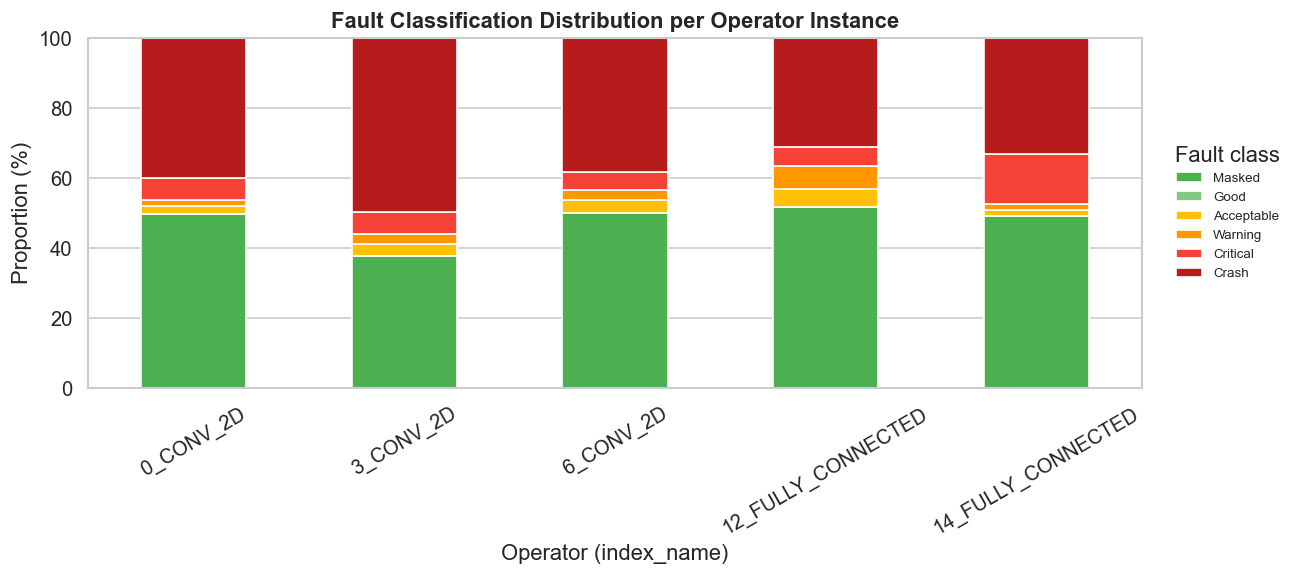

In [14]:
import numpy as np

# Combina operator_index + operator_name para distinguir instâncias do mesmo operador
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)
op_name = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
df["op_label"] = op_idx + "_" + op_name

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

# Ordena por op_index numérico (quando disponível) para manter ordem natural da rede
def _sort_key(label: str):
    head = label.split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

op_fc = op_fc.loc[sorted(op_fc.index, key=_sort_key)]

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den.loc[op_fc.index], axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator (index_name)")
ax.set_title("Fault Classification Distribution per Operator Instance", fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=False,
)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 7. Bit-Position Vulnerability Analysis
Evaluates whether higher-order bits (MSB) lead to more critical failures than lower-order bits (LSB).

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\3403739046.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bit_fc = df.groupby("bit_index").apply(


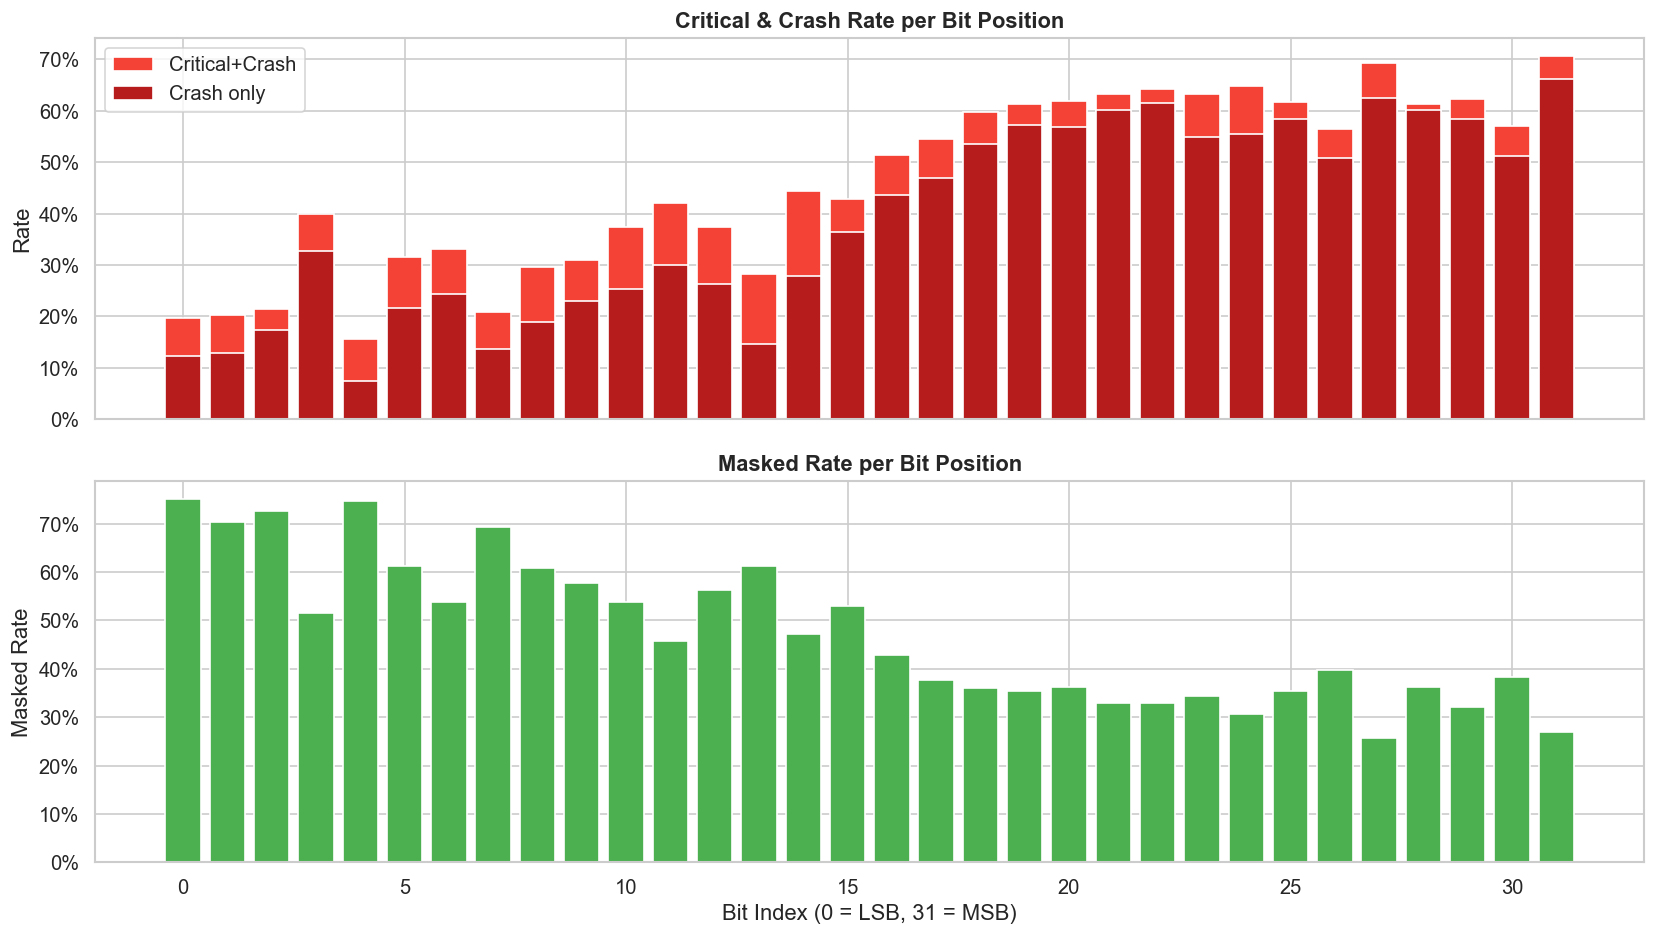

,bit_index,total,critical,degraded,crash,masked,critical_rate,crash_rate,masked_rate
0,0,3600,706,807,440,2704,0.1961,0.1222,0.7511
1,1,5100,1030,1252,657,3591,0.2020,0.1288,0.7041
2,2,4500,963,1051,783,3269,0.2140,0.1740,0.7264
3,3,4900,1953,2149,1600,2521,0.3986,0.3265,0.5145
4,4,5600,870,1088,415,4185,0.1554,0.0741,0.7473
5,5,4000,1262,1410,866,2448,0.3155,0.2165,0.6120
6,6,4400,1460,1770,1074,2368,0.3318,0.2441,0.5382
7,7,4300,899,1090,587,2984,0.2091,0.1365,0.6940
8,8,3400,1009,1150,645,2068,0.2968,0.1897,0.6082
9,9,5200,1610,1886,1193,3005,0.3096,0.2294,0.5779


In [15]:
bit_fc = df.groupby("bit_index").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "degraded": g["fault_class"].isin(DEGRADED_SET).sum(),
        "crash": (g["fault_class"] == "Crash").sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
    })
).reset_index()
bit_fc["bit_index"] = bit_fc["bit_index"].astype(int)
bit_fc["critical_rate"] = bit_fc["critical"] / bit_fc["total"]
bit_fc["crash_rate"] = bit_fc["crash"] / bit_fc["total"]
bit_fc["masked_rate"] = bit_fc["masked"] / bit_fc["total"]
bit_fc = bit_fc.sort_values("bit_index")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(bit_fc["bit_index"], bit_fc["critical_rate"], color="#F44336", label="Critical+Crash")
axes[0].bar(bit_fc["bit_index"], bit_fc["crash_rate"], color="#B71C1C", label="Crash only")
axes[0].set_ylabel("Rate")
axes[0].set_title("Critical & Crash Rate per Bit Position", fontweight="bold")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[1].bar(bit_fc["bit_index"], bit_fc["masked_rate"], color="#4CAF50")
axes[1].set_ylabel("Masked Rate")
axes[1].set_xlabel("Bit Index (0 = LSB, 31 = MSB)")
axes[1].set_title("Masked Rate per Bit Position", fontweight="bold")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability.png", bbox_inches="tight")
plt.show()

display(bit_fc.round(4))

## 8. Bit-Position Vulnerability by Register Class

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\3218813655.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bit_cls = df.groupby(["register_class", "bit_index"]).apply(


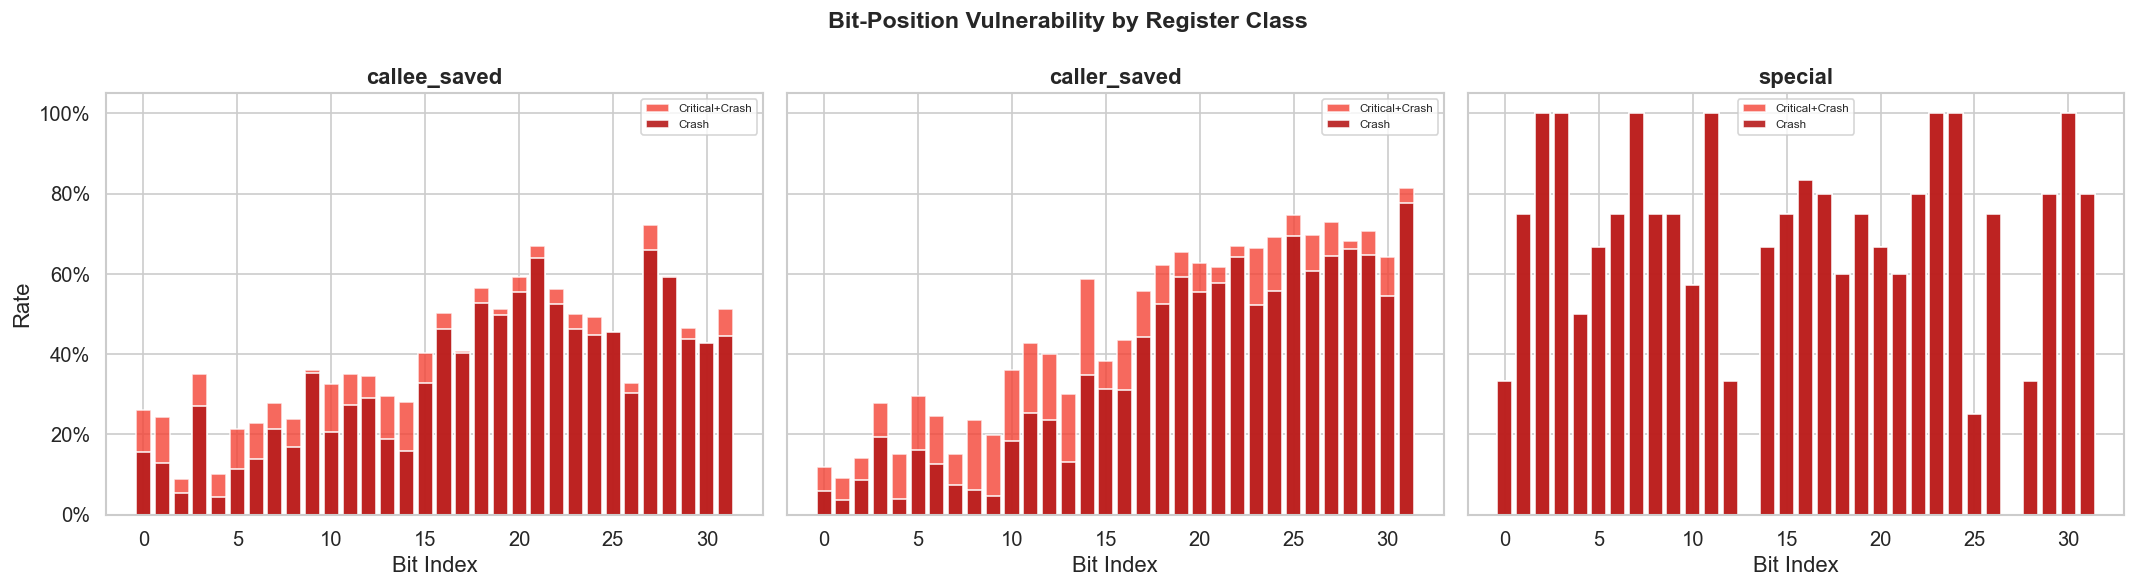

In [16]:
bit_cls = df.groupby(["register_class", "bit_index"]).apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0,
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g) if len(g) > 0 else 0,
    })
).reset_index()
bit_cls["bit_index"] = bit_cls["bit_index"].astype(int)

reg_classes = sorted(bit_cls["register_class"].unique())
fig, axes = plt.subplots(1, len(reg_classes), figsize=(6 * len(reg_classes), 5), sharey=True)
if len(reg_classes) == 1:
    axes = [axes]

for ax, rc in zip(axes, reg_classes):
    subset = bit_cls[bit_cls["register_class"] == rc].sort_values("bit_index")
    ax.bar(subset["bit_index"], subset["critical_rate"], color="#F44336", alpha=0.8, label="Critical+Crash")
    ax.bar(subset["bit_index"], subset["crash_rate"], color="#B71C1C", alpha=0.9, label="Crash")
    ax.set_title(f"{rc}", fontweight="bold")
    ax.set_xlabel("Bit Index")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.legend(fontsize=7)

axes[0].set_ylabel("Rate")
fig.suptitle("Bit-Position Vulnerability by Register Class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability_by_class.png", bbox_inches="tight")
plt.show()

## 9. Crash & Critical Failure Deep-Dive

Total critical/crash inferences: 63,877 (45.95%)
Unique faults causing critical/crash: 912 / 1390



fault_class,Crash,Critical,total_critical
register_name,,,
gp,5000,0,5000
sp,4400,0,4400
a2,3065,406,3471
ra,3400,0,3400
s0,2776,192,2968
a1,1700,989,2689
s3,2096,498,2594
a7,900,1437,2337
a4,1000,1334,2334


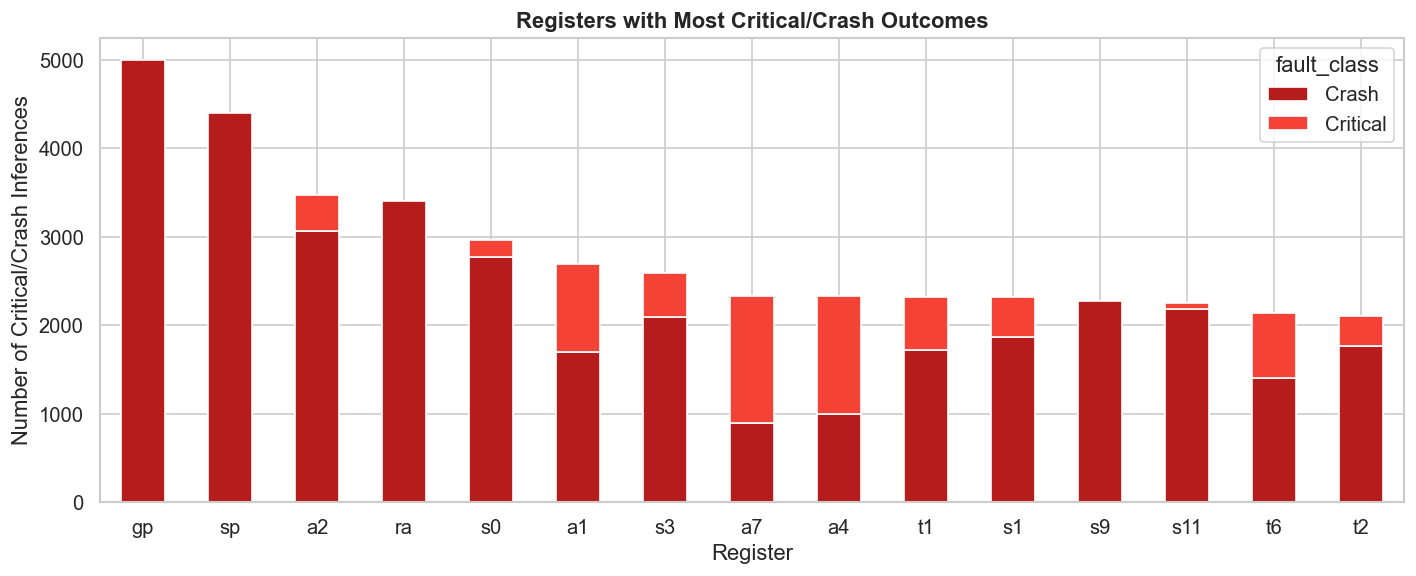

In [17]:
crit_df = df[df["fault_class"].isin(CRITICAL_SET)].copy()
print(f"Total critical/crash inferences: {len(crit_df):,} ({len(crit_df)/len(df)*100:.2f}%)")
print(f"Unique faults causing critical/crash: {crit_df['fault_id'].nunique()} / {df['fault_id'].nunique()}")
print()

# Which registers cause the most crashes?
crash_by_reg = crit_df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
crash_by_reg["total_critical"] = crash_by_reg.sum(axis=1)
crash_by_reg = crash_by_reg.sort_values("total_critical", ascending=False)
display(crash_by_reg.head(15))

# Top 10 most critical registers
fig, ax = plt.subplots(figsize=(12, 5))
top_crit_regs = crash_by_reg.head(15)
colors_stacked = []
for c in top_crit_regs.columns:
    if c == "total_critical":
        continue
    colors_stacked.append(SEVERITY_COLORS.get(c, "#999"))

plot_cols = [c for c in top_crit_regs.columns if c != "total_critical"]
top_crit_regs[plot_cols].plot.bar(stacked=True, ax=ax, color=colors_stacked, edgecolor="white")
ax.set_ylabel("Number of Critical/Crash Inferences")
ax.set_xlabel("Register")
ax.set_title("Registers with Most Critical/Crash Outcomes", fontweight="bold")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_crash_by_register.png", bbox_inches="tight")
plt.show()

## 10. Per-Fault Aggregated Vulnerability
For each unique fault injection, compute the fraction of images that were classified as critical/crash to identify the **most dangerous single-bit faults**.

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\504302691.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fault_agg = df.groupby("fault_id").apply(


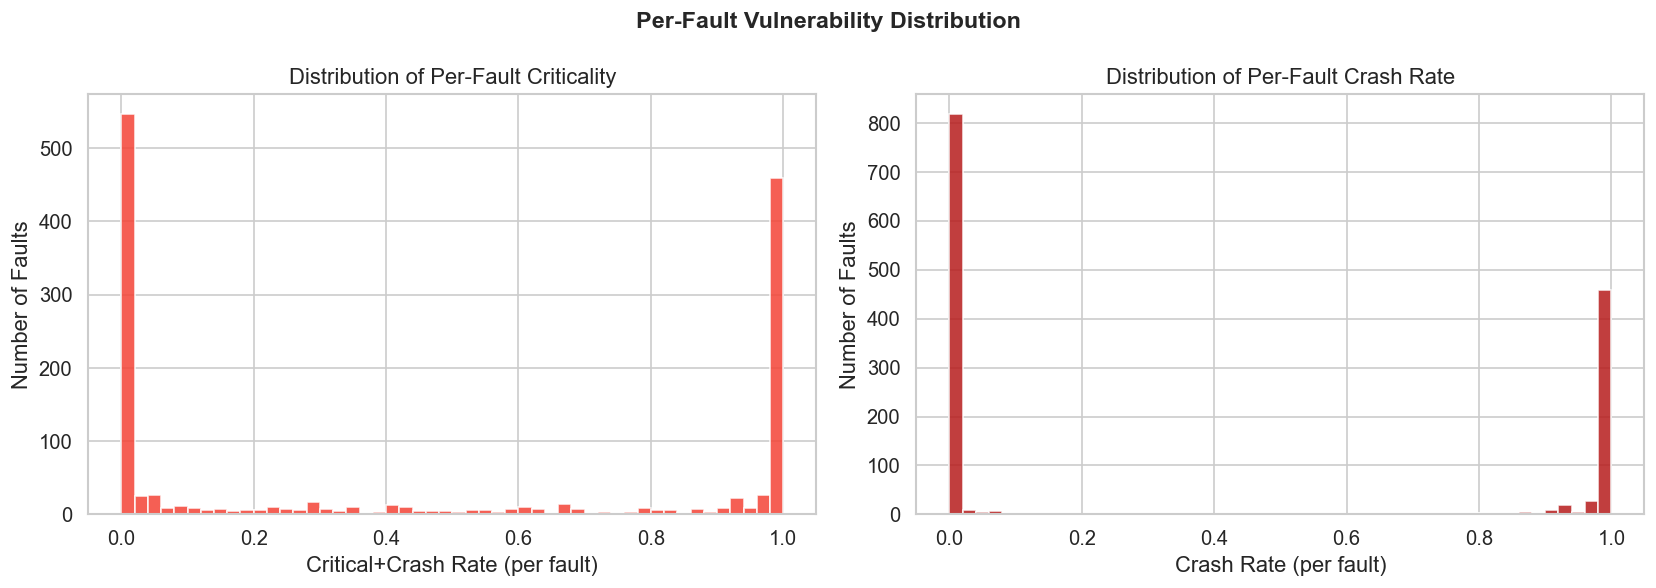


Top 20 most dangerous faults (by critical_rate):


,fault_id,register_name,register_class,bit_index,operator_index,operator_name,n_images,n_critical,n_crash,critical_rate,crash_rate
0,3.0,ra,caller_saved,3,0,CONV_2D,100,100,100,1.0,1.0
1,15.0,ra,caller_saved,15,0,CONV_2D,100,100,100,1.0,1.0
2,16.0,ra,caller_saved,16,0,CONV_2D,100,100,100,1.0,1.0
3,25.0,ra,caller_saved,25,0,CONV_2D,100,100,100,1.0,1.0
4,29.0,ra,caller_saved,29,0,CONV_2D,100,100,100,1.0,1.0
5,30.0,ra,caller_saved,30,0,CONV_2D,100,100,100,1.0,1.0
6,33.0,sp,special,1,0,CONV_2D,100,100,100,1.0,1.0
7,34.0,sp,special,2,0,CONV_2D,100,100,100,1.0,1.0
8,38.0,sp,special,6,0,CONV_2D,100,100,100,1.0,1.0
9,42.0,sp,special,10,0,CONV_2D,100,100,100,1.0,1.0


In [18]:
fault_agg = df.groupby("fault_id").apply(
    lambda g: pd.Series({
        "register_name": g["register_name"].iloc[0],
        "register_class": g["register_class"].iloc[0],
        "bit_index": int(g["bit_index"].iloc[0]),
        "operator_index": int(g["operator_index"].iloc[0]),
        "operator_name": g["operator_name"].iloc[0] if "operator_name" in g.columns else "",
        "n_images": len(g),
        "n_critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "n_crash": (g["fault_class"] == "Crash").sum(),
        "n_masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g),
    })
).reset_index()

# Distribution of per-fault critical rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fault_agg["critical_rate"], bins=50, color="#F44336", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Critical+Crash Rate (per fault)")
axes[0].set_ylabel("Number of Faults")
axes[0].set_title("Distribution of Per-Fault Criticality")

axes[1].hist(fault_agg["crash_rate"], bins=50, color="#B71C1C", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Crash Rate (per fault)")
axes[1].set_ylabel("Number of Faults")
axes[1].set_title("Distribution of Per-Fault Crash Rate")

fig.suptitle("Per-Fault Vulnerability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_per_fault_distribution.png", bbox_inches="tight")
plt.show()

# Top 20 most dangerous faults
print("\nTop 20 most dangerous faults (by critical_rate):")
display(fault_agg.nlargest(20, "critical_rate")[
    ["fault_id", "register_name", "register_class", "bit_index",
     "operator_index", "operator_name", "n_images", "n_critical",
     "n_crash", "critical_rate", "crash_rate"]
])

## 12. Register × Bit Heatmap (Critical Rate)

C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\2195538395.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)


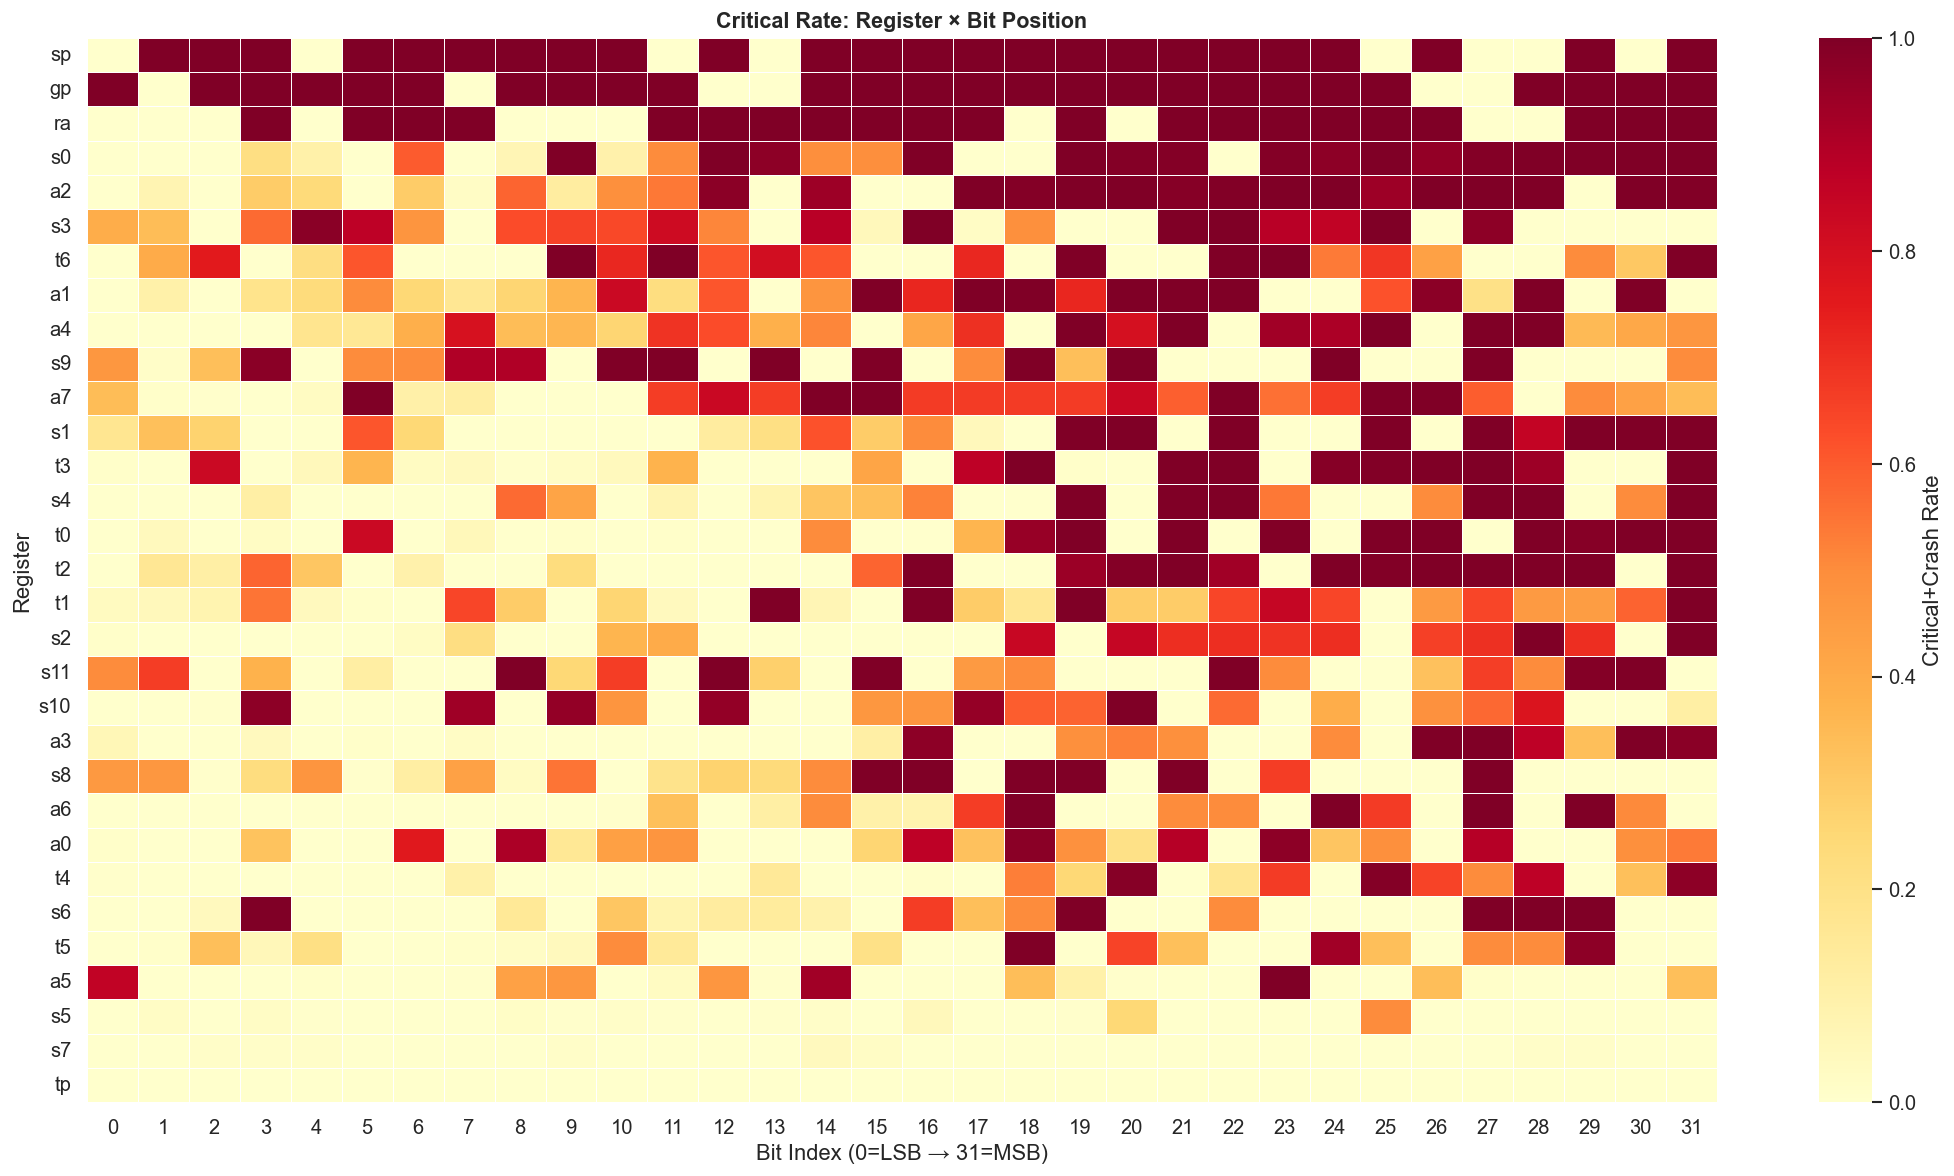

In [20]:
reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)
reg_bit_crit = reg_bit_crit.reindex(reg_order)
reg_bit_crit.columns = reg_bit_crit.columns.astype(int)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    reg_bit_crit, cmap="YlOrRd", linewidths=0.3, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical+Crash Rate"},
    vmin=0, vmax=max(reg_bit_crit.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Bit Position", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Bit Index (0=LSB → 31=MSB)")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_bit.png", bbox_inches="tight")
plt.show()

## 13. Impact on Model Accuracy
Compare the **golden accuracy** (no fault) against the effective accuracy under each fault scenario.

Golden Accuracy : 0.6140 (61.40%)
Faulty Accuracy : 0.5405 (54.05%)
Accuracy Drop   : 7.36 pp


C:\Users\ronal\AppData\Local\Temp\ipykernel_8836\3552998935.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc_per_reg = df.groupby("register_name").apply(


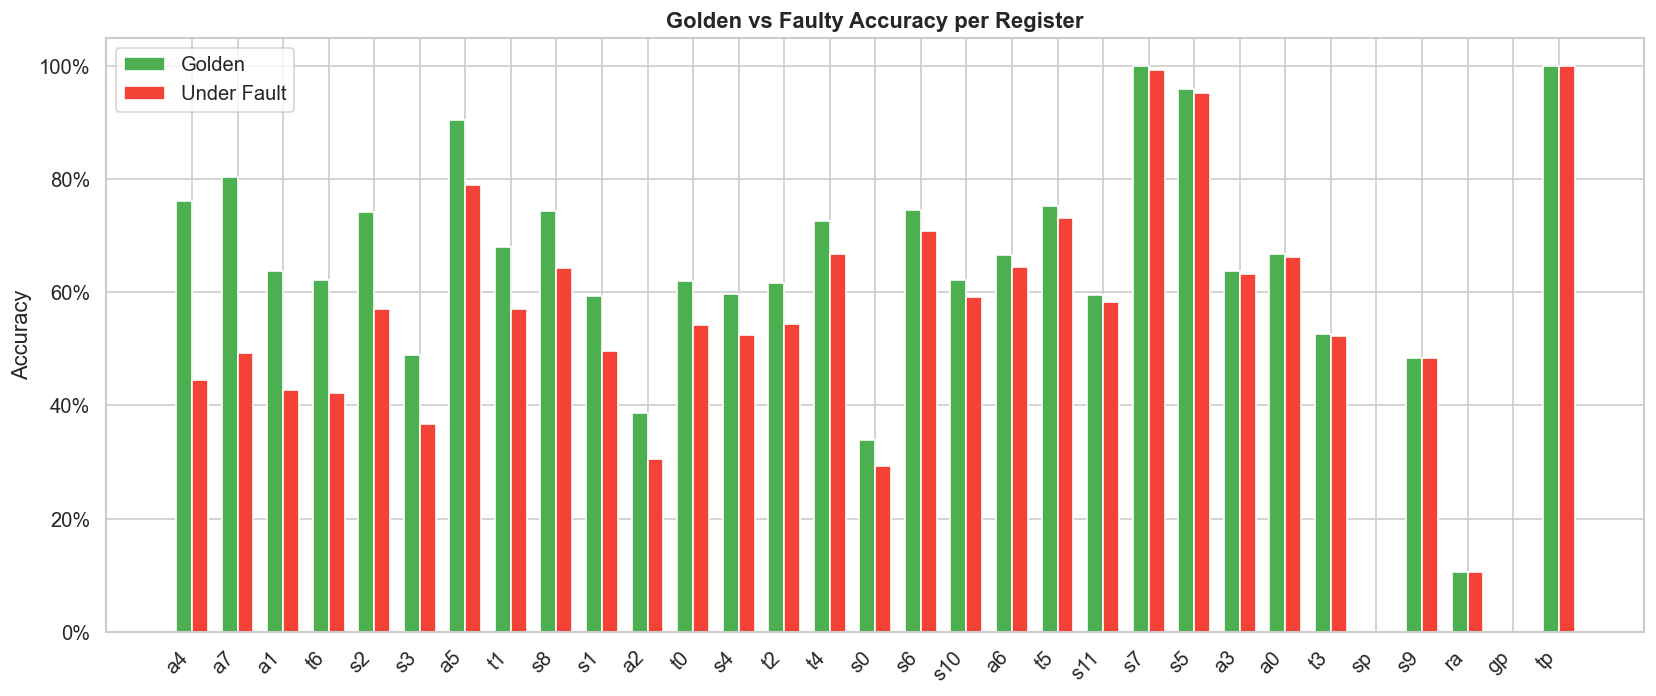

,faulty_accuracy,golden_accuracy,accuracy_drop
register_name,,,
a4,0.4443,0.7619,0.3176
a7,0.4920,0.8043,0.3124
a1,0.4279,0.6383,0.2104
t6,0.4224,0.6216,0.1992
s2,0.5709,0.7417,0.1709
s3,0.3673,0.4888,0.1215
a5,0.7900,0.9048,0.1148
t1,0.5698,0.6807,0.1109
s8,0.6429,0.7440,0.1010


In [21]:
# Golden accuracy
golden_correct = (df["golden_pred_class_ref"] == df["label"]).sum()
golden_acc = golden_correct / len(df)

# Faulty accuracy
faulty_correct = (df["pred_class"] == df["label"]).sum()
faulty_acc = faulty_correct / len(df)

print(f"Golden Accuracy : {golden_acc:.4f} ({golden_acc*100:.2f}%)")
print(f"Faulty Accuracy : {faulty_acc:.4f} ({faulty_acc*100:.2f}%)")
print(f"Accuracy Drop   : {(golden_acc - faulty_acc)*100:.2f} pp")

# Accuracy per register
acc_per_reg = df.groupby("register_name").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": ((g["golden_pred_class_ref"] == g["label"]).sum() - (g["pred_class"] == g["label"]).sum()) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(acc_per_reg))
w = 0.35
ax.bar(x - w/2, acc_per_reg["golden_accuracy"], w, label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_reg["faulty_accuracy"], w, label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_reg.index, rotation=45, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Golden vs Faulty Accuracy per Register", fontweight="bold")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_accuracy_per_register.png", bbox_inches="tight")
plt.show()

display(acc_per_reg.round(4))

## 14. Probability (Confidence) Degradation Analysis
For non-crash inferences, measure how fault injection affected the output confidence.

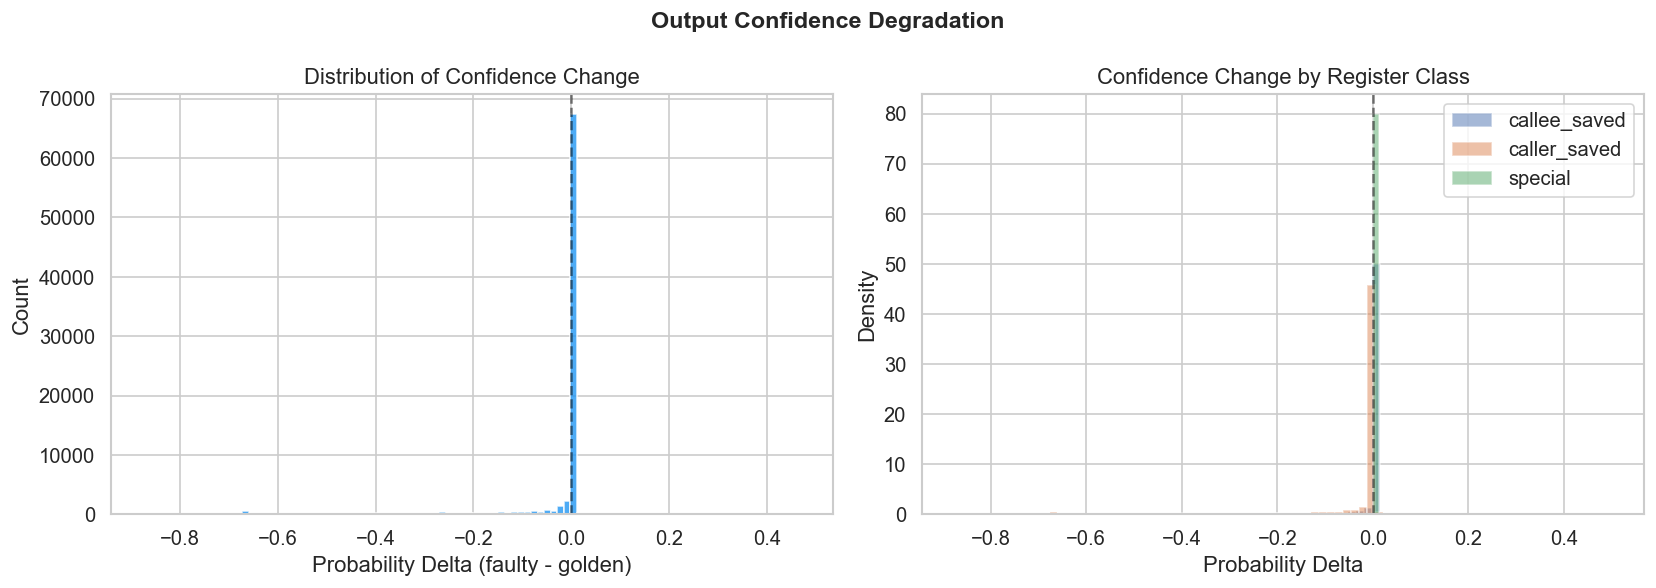

,mean,std,min,max
register_name,,,,
a4,-0.1713,0.2635,-0.8594,0.4688
s3,-0.1691,0.2856,-0.8359,0.3516
a1,-0.1415,0.2205,-0.7656,0.4688
a2,-0.1114,0.2039,-0.8125,0.4531
s2,-0.1094,0.1831,-0.7383,0.4297
a7,-0.0867,0.1650,-0.7695,0.4688
a5,-0.0846,0.2374,-0.8594,0.4688
s1,-0.0784,0.1738,-0.8359,0.4648
s0,-0.0771,0.1757,-0.7930,0.3320


In [22]:
ok_df = df[df["status"] == "ok"].copy()
ok_df["prob_delta"] = ok_df["top1_prob"] - ok_df["golden_top1_prob_ref"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ok_df["prob_delta"], bins=100, color="#2196F3", edgecolor="white", alpha=0.8)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Probability Delta (faulty - golden)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Confidence Change")

# Per register class
for rc in sorted(ok_df["register_class"].dropna().unique()):
    subset = ok_df[ok_df["register_class"] == rc]["prob_delta"]
    axes[1].hist(subset, bins=80, alpha=0.5, label=rc, density=True)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Probability Delta")
axes[1].set_ylabel("Density")
axes[1].set_title("Confidence Change by Register Class")
axes[1].legend()

fig.suptitle("Output Confidence Degradation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_confidence_degradation.png", bbox_inches="tight")
plt.show()

# Mean confidence delta per register
prob_stats = ok_df.groupby("register_name")["prob_delta"].agg(["mean", "std", "min", "max"]).sort_values("mean")
display(prob_stats.round(4))

## 15. Summary Table (LaTeX-ready)
Consolidated table for the paper.

In [23]:
# Build per-register summary
summary_rows = []
for reg, grp in df.groupby("register_name"):
    n = len(grp)
    reg_class = grp["register_class"].iloc[0] if "register_class" in grp.columns else "?"
    fc = grp["fault_class"].value_counts()
    n_masked = fc.get("Masked", 0)
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    n_crash = fc.get("Crash", 0)
    acc = (grp["pred_class"] == grp["label"]).sum() / n
    p_crit, lo, hi = wilson_ci(n_crit, n)
    summary_rows.append({
        "Register": reg,
        "Class": reg_class,
        "N": n,
        "Masked %": round(n_masked / n * 100, 2),
        "Critical %": round(n_crit / n * 100, 2),
        "Crash %": round(n_crash / n * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
        "Accuracy %": round(acc * 100, 2),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Critical %", ascending=False).reset_index(drop=True)
display(summary_df)

# Overall
overall_n = len(df)
overall_fc = df["fault_class"].value_counts()
overall_crit = overall_fc.get("Critical", 0) + overall_fc.get("Crash", 0)
p, lo, hi = wilson_ci(overall_crit, overall_n)
print(f"\nOverall Critical+Crash Rate: {p*100:.2f}% [95% CI: {lo*100:.2f}% – {hi*100:.2f}%]")
print(f"Total faults sampled: {df['fault_id'].nunique()} / {len(pop)} population")

# LaTeX export
latex_str = summary_df.to_latex(index=False, float_format="%.2f", caption="Register fault injection resilience summary.", label="tab:register_resilience")
print("\n--- LaTeX Table ---")
print(latex_str)

,Register,Class,N,Masked %,Critical %,Crash %,CI 95% low,CI 95% high,Accuracy %
0,sp,special,4400,0.00,100.00,100.00,99.91,100.00,0.00
1,gp,special,5000,0.00,100.00,100.00,99.92,100.00,0.00
2,ra,caller_saved,3800,10.53,89.47,89.47,88.46,90.41,10.53
3,s0,callee_saved,4200,22.86,70.67,66.10,69.27,72.02,29.33
4,a2,caller_saved,5000,21.04,69.42,61.30,68.13,70.68,30.58
5,s3,callee_saved,4100,30.27,63.27,51.12,61.78,64.73,36.73
6,t6,caller_saved,3700,31.65,57.76,37.84,56.16,59.34,42.24
7,a1,caller_saved,4700,23.30,57.21,36.17,55.79,58.62,42.79
8,a4,caller_saved,4200,24.12,55.57,23.81,54.06,57.07,44.43
9,s9,callee_saved,4400,48.23,51.66,51.66,50.18,53.13,48.34



Overall Critical+Crash Rate: 45.95% [95% CI: 45.69% – 46.22%]
Total faults sampled: 1390 / 4960 population

--- LaTeX Table ---
\begin{table}
\caption{Register fault injection resilience summary.}
\label{tab:register_resilience}
\begin{tabular}{llrrrrrrr}
\toprule
Register & Class & N & Masked % & Critical % & Crash % & CI 95% low & CI 95% high & Accuracy % \\
\midrule
sp & special & 4400 & 0.00 & 100.00 & 100.00 & 99.91 & 100.00 & 0.00 \\
gp & special & 5000 & 0.00 & 100.00 & 100.00 & 99.92 & 100.00 & 0.00 \\
ra & caller_saved & 3800 & 10.53 & 89.47 & 89.47 & 88.46 & 90.41 & 10.53 \\
s0 & callee_saved & 4200 & 22.86 & 70.67 & 66.10 & 69.27 & 72.02 & 29.33 \\
a2 & caller_saved & 5000 & 21.04 & 69.42 & 61.30 & 68.13 & 70.68 & 30.58 \\
s3 & callee_saved & 4100 & 30.27 & 63.27 & 51.12 & 61.78 & 64.73 & 36.73 \\
t6 & caller_saved & 3700 & 31.65 & 57.76 & 37.84 & 56.16 & 59.34 & 42.24 \\
a1 & caller_saved & 4700 & 23.30 & 57.21 & 36.17 & 55.79 & 58.62 & 42.79 \\
a4 & caller_saved & 4200 & 

## 16. Per Register-Class Summary (LaTeX-ready)

In [24]:
cls_summary = []
for rc, grp in df.groupby("register_class"):
    n = len(grp)
    fc = grp["fault_class"].value_counts()
    n_crit = fc.get("Critical", 0) + fc.get("Crash", 0)
    p, lo, hi = wilson_ci(n_crit, n)
    cls_summary.append({
        "Register Class": rc,
        "N": n,
        "Masked %": round(fc.get("Masked", 0) / n * 100, 2),
        "Acceptable %": round(fc.get("Acceptable", 0) / n * 100, 2),
        "Warning %": round(fc.get("Warning", 0) / n * 100, 2),
        "Critical %": round(fc.get("Critical", 0) / n * 100, 2),
        "Crash %": round(fc.get("Crash", 0) / n * 100, 2),
        "Crit+Crash %": round(p * 100, 2),
        "CI 95% low": round(lo * 100, 2),
        "CI 95% high": round(hi * 100, 2),
    })

cls_summary_df = pd.DataFrame(cls_summary).sort_values("Crit+Crash %", ascending=False).reset_index(drop=True)
display(cls_summary_df)

latex_cls = cls_summary_df.to_latex(index=False, float_format="%.2f", caption="Resilience by RISC-V register class.", label="tab:register_class_resilience")
print("\n--- LaTeX Table ---")
print(latex_cls)

,Register Class,N,Masked %,Acceptable %,Warning %,Critical %,Crash %,Crit+Crash %,CI 95% low,CI 95% high
0,special,13400,29.85,0.00,0.00,0.00,70.15,70.15,69.37,70.92
1,caller_saved,71000,45.14,4.09,4.24,10.01,36.52,46.53,46.17,46.90
2,callee_saved,54600,55.30,2.71,2.72,5.71,33.55,39.27,38.86,39.68



--- LaTeX Table ---
\begin{table}
\caption{Resilience by RISC-V register class.}
\label{tab:register_class_resilience}
\begin{tabular}{lrrrrrrrrr}
\toprule
Register Class & N & Masked % & Acceptable % & Warning % & Critical % & Crash % & Crit+Crash % & CI 95% low & CI 95% high \\
\midrule
special & 13400 & 29.85 & 0.00 & 0.00 & 0.00 & 70.15 & 70.15 & 69.37 & 70.92 \\
caller_saved & 71000 & 45.14 & 4.09 & 4.24 & 10.01 & 36.52 & 46.53 & 46.17 & 46.90 \\
callee_saved & 54600 & 55.30 & 2.71 & 2.72 & 5.71 & 33.55 & 39.27 & 38.86 & 39.68 \\
\bottomrule
\end{tabular}
\end{table}



## 17. Export Analysis Artifacts

In [25]:
export_dir = RUN_DIR / "notebook_exports"
export_dir.mkdir(exist_ok=True)

summary_df.to_csv(export_dir / "summary_per_register.csv", index=False)
cls_summary_df.to_csv(export_dir / "summary_per_register_class.csv", index=False)
ci_df.to_csv(export_dir / "confidence_intervals.csv", index=False)
bit_fc.to_csv(export_dir / "bit_vulnerability.csv", index=False)
fault_agg.to_csv(export_dir / "per_fault_aggregated.csv", index=False)
reg_fc.to_csv(export_dir / "classification_per_register.csv")
op_fc.to_csv(export_dir / "classification_per_operator.csv")

print(f"Exported {len(list(export_dir.glob('*')))} files to {export_dir}")
for f in sorted(export_dir.glob("*")):
    print(f"  {f.name} ({f.stat().st_size:,} bytes)")

Exported 7 files to notebook_exports
  bit_vulnerability.csv (2,636 bytes)
  classification_per_operator.csv (521 bytes)
  classification_per_register.csv (2,062 bytes)
  confidence_intervals.csv (3,715 bytes)
  per_fault_aggregated.csv (84,216 bytes)
  summary_per_register.csv (1,823 bytes)
  summary_per_register_class.csv (291 bytes)
